# Q4. Which products make the profit, as opposed to the revenue?

**Decision it informs:** reprice, promote or delist.

**Scope:** valid order items, January 2015 to September 2017 (100 products sold in the window).

**Method:** ABC / Pareto by profit next to Pareto by revenue; a "sells well, loses money" screen; and a check of
where the loss-making order lines come from.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from scdd.db import connect, q, run_analysis
from scdd import style
from scdd.stats import cramers_v, save_findings

style.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = connect()

## 1. Pareto: profit vs revenue
Sources: `sql/analysis/p5_product_pareto.sql`, `sql/analysis/p5_kpis.sql`.

In [2]:
par = run_analysis("p5_product_pareto.sql", con)
kpi = run_analysis("p5_kpis.sql", con).iloc[0]
rev_sorted = par.sort_values("revenue", ascending=False)
abc = par.groupby("abc_class").agg(products=("product_key", "size"), profit=("profit", "sum"), revenue=("revenue", "sum"))
abc["profit_share"] = abc.profit / abc.profit.sum(); abc["revenue_share"] = abc.revenue / abc.revenue.sum()
rho = stats.spearmanr(par.profit_rank, par.revenue_rank)
print(f"{int(kpi.products)} products. Top 20% ({int(kpi.top_20pct_products)}) by profit earn {kpi.top_20pct_profit_share:.1%} of profit; "
      f"top 20% by revenue earn {kpi.top_20pct_revenue_share:.1%} of revenue. Spearman rank correlation of profit "
      f"and revenue ranks: {rho.statistic:.3f}")
display(abc)
par[["profit_rank", "revenue_rank", "product_name", "category_name", "revenue", "profit", "profit_margin",
     "cum_profit_share", "abc_class"]].head(12)

100 products. Top 20% (20) by profit earn 96.1% of profit; top 20% by revenue earn 96.1% of revenue. Spearman rank correlation of profit and revenue ranks: 0.904


,products,profit,revenue,profit_share,revenue_share
abc_class,,,,,
A,7,"2,914,483.3800","24,295,041.0700",0.8256,0.8246
B,5,"439,863.7700","3,730,236.4200",0.1246,0.1266
C,88,"175,598.7400","1,438,466.6800",0.0497,0.0488


,profit_rank,revenue_rank,product_name,category_name,revenue,profit,profit_margin,cum_profit_share,abc_class
0,1,1,Field & Stream Sportsman 16 Gun Fire Safe,Fishing,"5,959,337.5800","730,159.1200",0.1225,0.2068,A
1,2,2,Perfect Fitness Perfect Rip Deck,Cleats,"3,799,352.2600","472,867.7900",0.1245,0.3408,A
2,3,3,Diamondback Women's Serene Classic Comfort Bi,Camping & Hiking,"3,542,457.9800","409,215.2400",0.1155,0.4567,A
3,4,4,Nike Men's Free 5.0+ Running Shoe,Cardio Equipment,"3,146,040.2600","358,365.1300",0.1139,0.5583,A
4,5,5,Nike Men's Dri-FIT Victory Golf Polo,Women's Apparel,"2,703,228.5000","334,162.5700",0.1236,0.6529,A
5,6,6,Pelican Sunstream 100 Kayak,Water Sports,"2,662,238.8500","307,522.8000",0.1155,0.7400,A
6,7,7,O'Brien Men's Neoprene Life Vest,Indoor/Outdoor Games,"2,482,385.6400","302,190.7300",0.1217,0.8256,A
7,8,8,Nike Men's CJ Elite 2 TD Football Cleat,Men's Footwear,"2,480,323.5200","296,357.1200",0.1195,0.9096,B
8,9,9,Under Armour Girls' Toddler Spine Surge Runni,Shop By Sport,"1,091,131.8700","121,568.9600",0.1114,0.9440,B
9,10,12,adidas Men's F10 Messi TRX FG Soccer Cleat,Baseball & Softball,"48,898.2600","8,078.2300",0.1652,0.9463,B


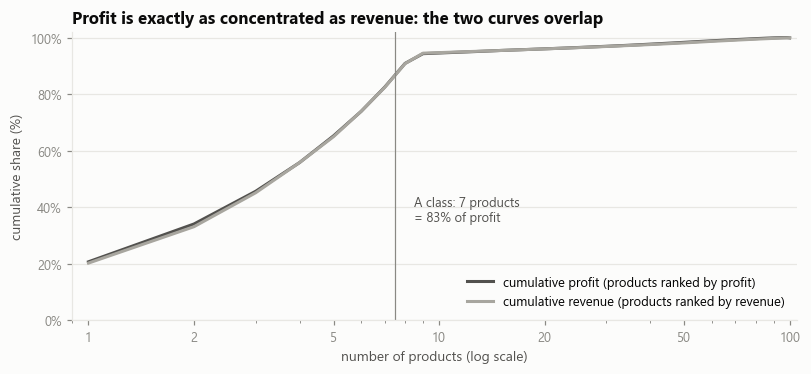

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
x = np.arange(1, len(par) + 1)
ax.plot(x, par.cum_profit_share, color=style.INK_2, lw=2, label="cumulative profit (products ranked by profit)")
ax.plot(x, rev_sorted.cum_revenue_share_by_revenue_rank, color=style.GREY, lw=2,
        label="cumulative revenue (products ranked by revenue)")
n_a = int((par.abc_class == "A").sum())
ax.axvline(n_a + 0.5, color=style.INK_MUTED, lw=0.8)
ax.text(n_a + 1.5, 0.35, f"A class: {n_a} products\n= {abc.loc['A', 'profit_share']:.0%} of profit", fontsize=8.5, color=style.INK_2)
ax.set_xscale("log"); ax.set_xlim(0.9, len(par) + 5)
ax.set_xticks([1, 2, 5, 10, 20, 50, 100], ["1", "2", "5", "10", "20", "50", "100"])
style.pct(ax); ax.set_ylim(0, 1.02)
ax.set_xlabel("number of products (log scale)"); ax.set_ylabel("cumulative share (%)")
ax.set_title("Profit is exactly as concentrated as revenue: the two curves overlap")
ax.legend(loc="lower right")
style.save(fig, "q4_pareto")
plt.show()

## 2. "Sells well, loses money"
Source: `sql/analysis/p5_sells_well_loses_money.sql`. Top-half revenue products with margin under 10%, plus any
loss-making product.

In [4]:
swlm = run_analysis("p5_sells_well_loses_money.sql", con)
swlm

,product_name,category_name,revenue,profit,profit_margin,order_items,loss_line_share,loss_from_negative_lines,flag
0,Titleist Pro V1x Golf Balls,Electronics,"36,687.8900","3,493.8400",0.0952,282,0.1879,"-5,420.6800","top-half revenue, margin < 10%"
1,Clicgear Rovic Cooler Bag,Golf Gloves,"29,596.8100","2,746.5400",0.0928,275,0.1855,"-4,338.5800","top-half revenue, margin < 10%"
2,ENO Atlas Hammock Straps,Hunting & Shooting,"25,986.1400","2,194.4700",0.0844,312,0.1955,"-3,472.3300","top-half revenue, margin < 10%"
3,Bridgestone e6 Straight Distance NFL San Dieg,Electronics,"24,970.4000","1,762.6300",0.0706,299,0.1940,"-4,104.2000","top-half revenue, margin < 10%"
4,Columbia Men's PFG Anchor Tough T-Shirt,Shop By Sport,"24,137.1000","2,340.5700",0.0970,292,0.1918,"-3,218.5900","top-half revenue, margin < 10%"
5,Under Armour Women's Ignite PIP VI Slide,Electronics,"23,583.4100","1,927.1100",0.0817,273,0.2088,"-3,049.7800","top-half revenue, margin < 10%"
6,Merrell Women's Grassbow Sport Hiking Shoe,Men's Golf Clubs,"18,664.6000","1,818.6500",0.0974,70,0.1429,"-3,096.7800","top-half revenue, margin < 10%"
7,Nike Men's Free TR 5.0 TB Training Shoe,As Seen on TV!,"17,917.6700","1,448.5200",0.0808,66,0.1970,"-2,470.1700","top-half revenue, margin < 10%"
8,Nike Women's Free 5.0 TR FIT PRT 4 Training S,Boxing & MMA,"16,730.1000","1,386.3600",0.0829,67,0.2537,"-2,812.9900","top-half revenue, margin < 10%"
9,SOLE E35 Elliptical,Strength Training,"9,779.9400",-724.4700,-0.0741,6,0.3333,"-2,198.6500",loss-making


Are the low-margin products genuinely different, or just small samples? Margin per product is noisy when a
product has a few hundred lines. Compare each flagged product's margin with the overall margin using a bootstrap
interval.

In [5]:
lines = q("""
    SELECT p.product_name, f.profit, f.item_total, f.discount_rate, p.category_name
    FROM fact_order_items f JOIN dim_product p USING (product_key)
    WHERE f.is_valid_order AND f.order_date < DATE '2017-10-01'
""", con)
overall_margin = lines.profit.sum() / lines.item_total.sum()
rng = np.random.default_rng(11)
rows = []
for name in swlm.product_name:
    sub = lines[lines.product_name == name]
    boots = [sub.profit.values[i].sum() / sub.item_total.values[i].sum()
             for i in (rng.integers(0, len(sub), len(sub)) for _ in range(400))]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append({"product_name": name, "lines": len(sub), "margin": sub.profit.sum() / sub.item_total.sum(),
                 "ci_low": lo, "ci_high": hi, "below_overall": hi < overall_margin})
flag_ci = pd.DataFrame(rows)
print(f"Overall margin {overall_margin:.2%}. Flagged products whose 95% interval sits wholly below it: "
      f"{int(flag_ci.below_overall.sum())} of {len(flag_ci)}")
flag_ci

Overall margin 11.98%. Flagged products whose 95% interval sits wholly below it: 1 of 11


,product_name,lines,margin,ci_low,ci_high,below_overall
0,Titleist Pro V1x Golf Balls,282,0.0952,0.0214,0.1591,False
1,Clicgear Rovic Cooler Bag,275,0.0928,0.0267,0.1575,False
2,ENO Atlas Hammock Straps,312,0.0844,0.0217,0.1457,False
3,Bridgestone e6 Straight Distance NFL San Dieg,299,0.0706,-0.0018,0.1341,False
4,Columbia Men's PFG Anchor Tough T-Shirt,292,0.0970,0.0328,0.1573,False
5,Under Armour Women's Ignite PIP VI Slide,273,0.0817,0.0166,0.1328,False
6,Merrell Women's Grassbow Sport Hiking Shoe,70,0.0974,-0.0697,0.2386,False
7,Nike Men's Free TR 5.0 TB Training Shoe,66,0.0808,-0.0381,0.2039,False
8,Nike Women's Free 5.0 TR FIT PRT 4 Training S,67,0.0829,-0.0788,0.2097,False
9,SOLE E35 Elliptical,6,-0.0741,-0.4413,0.2915,False


## 3. Where do loss-making lines come from?
Almost a fifth of order lines lose money. If some products or discount bands produced most of them, delisting or
repricing would help. Test whether the loss-line share differs by product (products with ≥ 200 lines), by
category and by discount band.

In [6]:
lines["loss"] = lines.profit < 0
big = lines.groupby("product_name").filter(lambda d: len(d) >= 200)
tests = {}
for label, frame, col in [("product", big, "product_name"), ("category", lines, "category_name")]:
    chi2, p, v = cramers_v(pd.crosstab(frame[col], frame.loss))
    tests[label] = {"p_value": p, "cramers_v": v, "min": frame.groupby(col).loss.mean().min(), "max": frame.groupby(col).loss.mean().max()}
lines["band"] = pd.cut(lines.discount_rate, [-0.001, 0.0499, 0.0999, 0.1499, 0.1999, 0.26],
                       labels=["0-5%", "5-10%", "10-15%", "15-20%", "20-25%"])
chi2, p, v = cramers_v(pd.crosstab(lines.band, lines.loss))
tests["discount band"] = {"p_value": p, "cramers_v": v, "min": lines.groupby("band", observed=True).loss.mean().min(),
                          "max": lines.groupby("band", observed=True).loss.mean().max()}
loss_share = lines.loss.mean()
print(f"Loss-making lines: {loss_share:.1%} of valid lines, losing ${-lines.loc[lines.loss, 'profit'].sum():,.0f} in the window")
pd.DataFrame(tests).T

Loss-making lines: 18.7% of valid lines, losing $3,461,393 in the window


,p_value,cramers_v,min,max
product,0.7151,0.0170,0.1343,0.2245
category,0.6411,0.0130,0.0984,0.2171
discount band,0.4969,0.0045,0.1839,0.1885


## Finding → number → decision

In [7]:
loss_products = par[par.profit < 0]
findings = {
    "products": int(kpi.products),
    "top20_profit_share": kpi.top_20pct_profit_share, "top20_revenue_share": kpi.top_20pct_revenue_share,
    "a_class_products": n_a, "a_class_profit_share": abc.loc["A", "profit_share"],
    "spearman_profit_revenue_rank": rho.statistic,
    "loss_making_products": int(kpi.loss_making_products),
    "loss_making_products_detail": loss_products[["product_name", "revenue", "profit", "order_items"]].to_dict(orient="records"),
    "flagged_low_margin": int(len(swlm)), "flagged_below_overall_ci": int(flag_ci.below_overall.sum()),
    "overall_margin": overall_margin,
    "loss_line_share": loss_share, "loss_line_amount": -lines.loc[lines.loss, "profit"].sum(),
    "loss_line_tests": tests,
    "a_class_list": par.loc[par.abc_class == "A", ["product_name", "profit", "profit_margin"]].to_dict(orient="records"),
}
save_findings("q4", findings)
display(Markdown(f"""
**Finding.** Profit is exactly as concentrated as revenue. The top {int(kpi.top_20pct_products)} products ({kpi.top_20pct_profit_share:.1%} of profit
vs {kpi.top_20pct_revenue_share:.1%} of revenue) are near-identical lists (rank correlation {rho.statistic:.2f}), and the **{n_a} A-class products
earn {abc.loc['A', 'profit_share']:.0%} of profit**. No high-revenue product loses money: only {int(kpi.loss_making_products)} products do, with
${-loss_products.profit.sum():,.0f} of losses between them. The {loss_share:.1%} of order lines that lose money are spread evenly across products,
categories and discount bands (Cramér's V ≤ {max(t['cramers_v'] for t in tests.values()):.3f}).

**Number.** {len(swlm)} products are flagged as "sells well, low margin", but {'none' if flag_ci.below_overall.sum() == 0 else int(flag_ci.below_overall.sum())}
{'has' if flag_ci.below_overall.sum() == 1 else 'have'} a margin interval wholly below the {overall_margin:.1%} average; the rest are small-sample noise.

**Decision.** No delisting or repricing case at product level beyond the {int(kpi.loss_making_products)} loss-making ellipticals (immaterial).
Product mix is not the profit lever; the discount policy (Q2) is. Run the discount-cap test on the {n_a} A-class products first,
where {abc.loc['A', 'profit_share']:.0%} of profit is at stake and volume is large enough to read a result in four weeks.
"""))


**Finding.** Profit is exactly as concentrated as revenue. The top 20 products (96.1% of profit
vs 96.1% of revenue) are near-identical lists (rank correlation 0.90), and the **7 A-class products
earn 83% of profit**. No high-revenue product loses money: only 2 products do, with
$3,244 of losses between them. The 18.7% of order lines that lose money are spread evenly across products,
categories and discount bands (Cramér's V ≤ 0.017).

**Number.** 11 products are flagged as "sells well, low margin", but 1
has a margin interval wholly below the 12.0% average; the rest are small-sample noise.

**Decision.** No delisting or repricing case at product level beyond the 2 loss-making ellipticals (immaterial).
Product mix is not the profit lever; the discount policy (Q2) is. Run the discount-cap test on the 7 A-class products first,
where 83% of profit is at stake and volume is large enough to read a result in four weeks.
